In [2]:
#SETUP#

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# load dataset
csv_df = pd.read_csv("data/analysis_output_full.csv")

# check the dataset
csv_df.head()

,customer_name,customer_branch,file_name,order_quantity,id,path,bounding_box_width_mm,bounding_box_height_mm,bounding_box_area_mm^2,part_area_mm^2,aspect_ratio,rectangularity_score,extraction_method,automation_index,number_of_holes,cutting_length_mm,cutting_time_s
0,MetalForm SA,Frankfurt Branch,Geo (1).DXF,1600,1,10991360/Geo (1).DXF,1600.219048,305.139765,4.882905e+05,4.013592e+04,0.190686,0.082197,Master,1,0,3438.024977,331.281499
1,MetalForm SA,Frankfurt Branch,Geo (57).DXF,500,1,10991360/Geo (57).DXF,1453.993892,1104.818310,1.606399e+06,1.520242e+06,0.759851,0.946366,Master,1,27,8584.200459,721.052028
2,MetalForm SA,Frankfurt Branch,Geo (37).DXF,1800,1,10991360/Geo (37).DXF,1947.204525,1134.770001,2.209629e+06,1.517175e+06,0.582769,0.686620,Master,1,31,8330.442132,717.826528
3,MetalForm SA,Frankfurt Branch,Geo (44).DXF,700,1,10991360/Geo (44).DXF,1097.000000,172.968300,1.897462e+05,1.894595e+05,0.157674,0.998489,Master,1,4,2609.913223,293.594793
4,MetalForm SA,Frankfurt Branch,Geo (19).DXF,1450,1,10991360/Geo (19).DXF,1152.727829,314.994358,3.631028e+05,3.631028e+05,0.273260,1.000000,Master,1,0,2935.444373,301.126662


In [3]:
# display all column names
print(csv_df.columns.tolist())

['customer_name', 'customer_branch', 'file_name', 'order_quantity', 'id', 'path', 'bounding_box_width_mm', 'bounding_box_height_mm', 'bounding_box_area_mm^2', 'part_area_mm^2', 'aspect_ratio', 'rectangularity_score', 'extraction_method', 'automation_index', 'number_of_holes', 'cutting_length_mm', 'cutting_time_s']


In [4]:
# select relevant features
correlation_df = csv_df[[
    "file_name",
    "cutting_length_mm",
    "number_of_holes",
    "part_area_mm^2",
    "bounding_box_area_mm^2",
    "bounding_box_width_mm",
    "bounding_box_height_mm",
    "aspect_ratio",
    "rectangularity_score",
    "cutting_time_s"
]].copy()

# remove duplicate parts
correlation_df = correlation_df.drop_duplicates(subset="file_name")

# select numeric columns
correlation_df = correlation_df.select_dtypes(include="number")

# check the dataset
print(correlation_df.shape)
correlation_df.head()

(80, 9)


,cutting_length_mm,number_of_holes,part_area_mm^2,bounding_box_area_mm^2,bounding_box_width_mm,bounding_box_height_mm,aspect_ratio,rectangularity_score,cutting_time_s
0,3438.024977,0,4.013592e+04,4.882905e+05,1600.219048,305.139765,0.190686,0.082197,331.281499
1,8584.200459,27,1.520242e+06,1.606399e+06,1453.993892,1104.818310,0.759851,0.946366,721.052028
2,8330.442132,31,1.517175e+06,2.209629e+06,1947.204525,1134.770001,0.582769,0.686620,717.826528
3,2609.913223,4,1.894595e+05,1.897462e+05,1097.000000,172.968300,0.157674,0.998489,293.594793
4,2935.444373,0,3.631028e+05,3.631028e+05,1152.727829,314.994358,0.273260,1.000000,301.126662


In [5]:
# calculate pearson correlation
correlation_matrix = correlation_df.corr(method="pearson")

# display correlation matrix
correlation_matrix

,cutting_length_mm,number_of_holes,part_area_mm^2,bounding_box_area_mm^2,bounding_box_width_mm,bounding_box_height_mm,aspect_ratio,rectangularity_score,cutting_time_s
cutting_length_mm,1.000000,0.769059,0.813559,0.830756,0.699179,0.801152,-0.016636,-0.010611,0.985935
number_of_holes,0.769059,1.000000,0.587952,0.501427,0.275614,0.495811,0.106254,0.079438,0.864419
part_area_mm^2,0.813559,0.587952,1.000000,0.941593,0.662385,0.903041,0.101556,0.180784,0.791658
bounding_box_area_mm^2,0.830756,0.501427,0.941593,1.000000,0.706786,0.949576,0.094441,-0.021653,0.782667
bounding_box_width_mm,0.699179,0.275614,0.662385,0.706786,1.000000,0.617285,-0.434713,0.000297,0.621874
bounding_box_height_mm,0.801152,0.495811,0.903041,0.949576,0.617285,1.000000,0.252477,-0.096922,0.756198
aspect_ratio,-0.016636,0.106254,0.101556,0.094441,-0.434713,0.252477,1.000000,-0.207772,0.006777
rectangularity_score,-0.010611,0.079438,0.180784,-0.021653,0.000297,-0.096922,-0.207772,1.000000,0.015786
cutting_time_s,0.985935,0.864419,0.791658,0.782667,0.621874,0.756198,0.006777,0.015786,1.000000


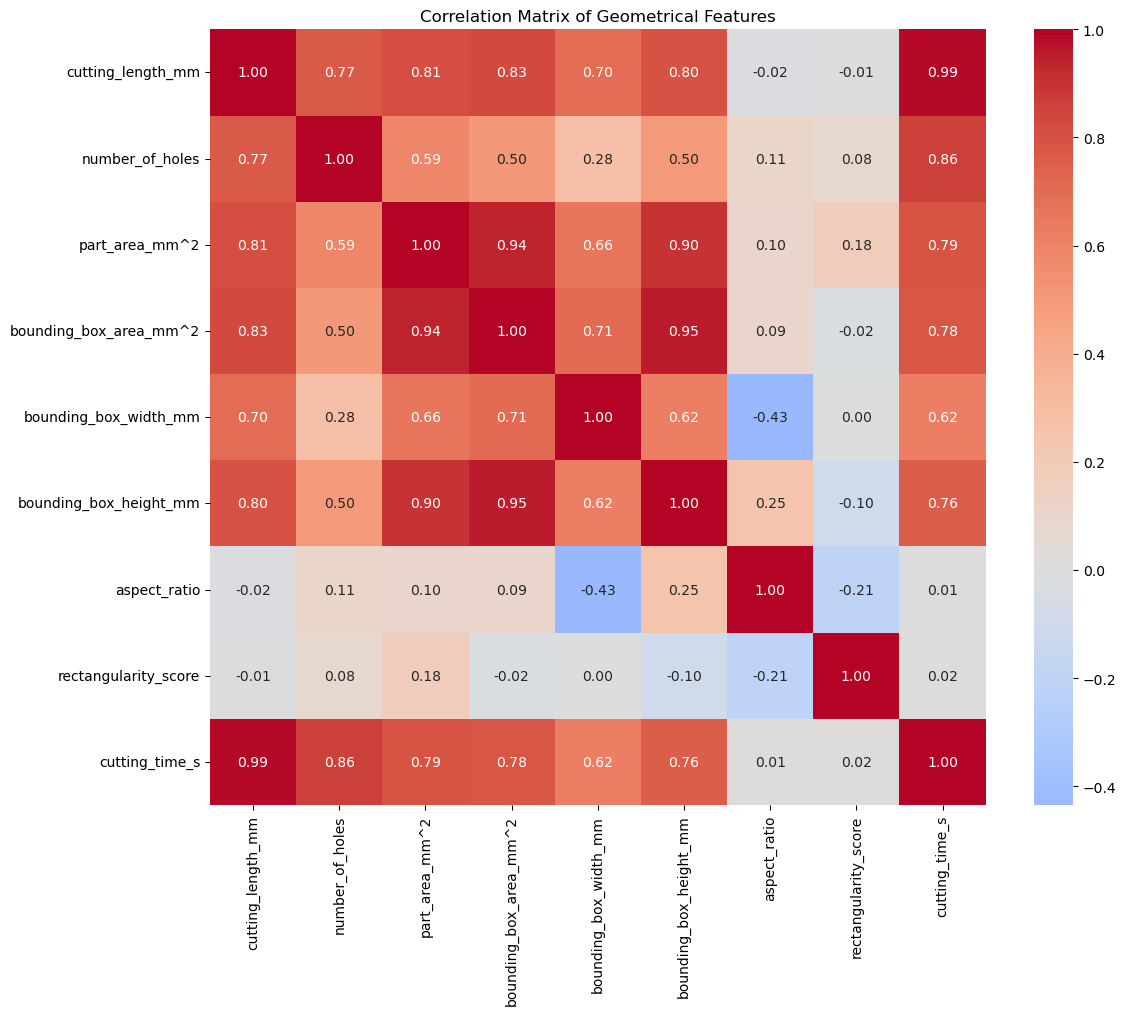

In [6]:
# plot correlation matrix
plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,          # displays correlation values
    cmap="coolwarm",     # uses a color gradient
    center=0,            # centers the colors at zero
    fmt=".2f",           # rounds values to two decimal places
    square=True          # makes cells square
)

plt.title("Correlation Matrix of Geometrical Features")
plt.tight_layout()
plt.show()

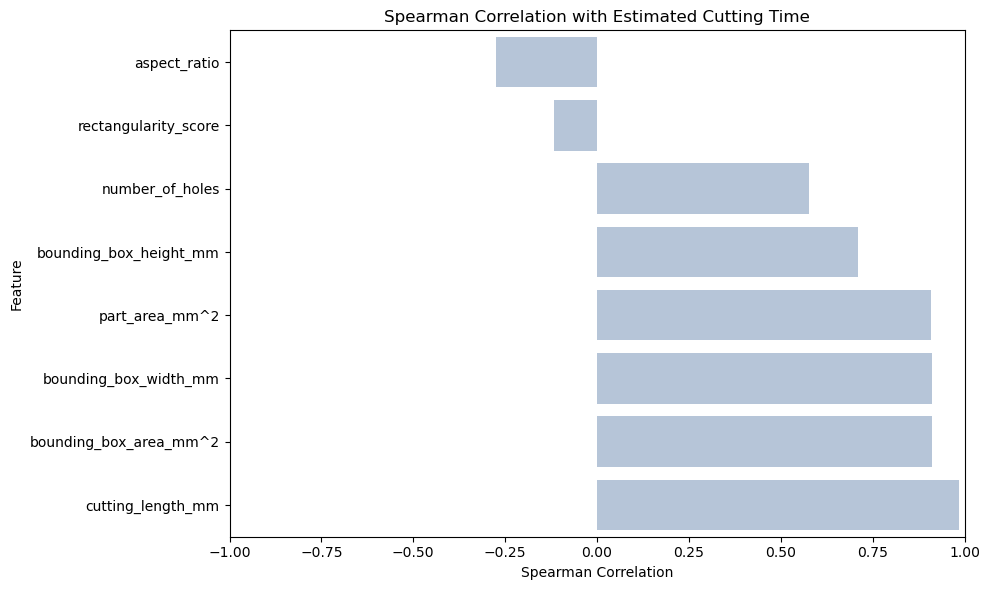

In [7]:
# calculate spearman correlation
spearman_matrix = correlation_df.corr(method="spearman")

# extract correlations with cutting time
spearman_corr = spearman_matrix["cutting_time_s"].drop(
    "cutting_time_s"
).sort_values()

# plot correlations
plt.figure(figsize=(10, 6))

sns.barplot(
    x=spearman_corr.values,
    y=spearman_corr.index,
    color="lightsteelblue"
)

plt.title("Spearman Correlation with Estimated Cutting Time")
plt.xlabel("Spearman Correlation")
plt.ylabel("Feature")
plt.xlim(-1, 1)

plt.tight_layout()
plt.show()